# 01. Membangun gold set manusia vs AI

**Pertanyaan:** bagaimana mendapat set uji berlabel tanpa anotator, dan tanpa membiarkan detektor
"curang" lewat petunjuk yang bukan gaya penulisan?

**Jawaban:** label manusia datang gratis dari **tanggal terbit**. ChatGPT rilis 30 November 2022, jadi
abstrak yang terbit sebelum 31 Oktober 2022 (margin satu bulan) dijamin bukan hasil AI generatif. Sisi AI
dibuat sekarang oleh beberapa model dari **judul yang sama**. Filter tanggal hanya berlaku untuk sisi
manusia: tulisan manusia tidak berubah sejak 2022.

```
OpenAlex (language:id, type:article, ≤ 2022-10-31) ──► abstrak manusia ─┐
                                                                         ├─► gold_set.csv (+ split train/test)
judul yang sama ─► 3 model Groq × 4 gaya prompt ─► abstrak AI ──────────┘
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import config

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)
config.ensure_dirs()
GOLD = config.GOLD_DIR / "gold_set.csv"

In [2]:
from src import build_gold_set as bgs
from src import generate, openalex

# --- Parameter. TARGET kecil agar notebook cepat; gold set penuh memakai 500 (cache melanjutkan, bukan mengulang).
TARGET = 60
INCLUDE_MIXED = False   # kelas campuran: teks manusia dipoles AI
SPLIT_BY = "work"       # "work" menjaga pasangan manusia-AI satu sisi; "field" menguji lintas bidang ilmu
SLEEP = 1.0             # jeda antar generasi; lihat catatan "kebocoran generator" di bawah
SEED = 42

pd.Series(
    {
        "batas akhir teks manusia": config.HUMAN_CUTOFF_DATE,
        "mulai": config.HUMAN_START_DATE,
        "panjang abstrak": f"{config.MIN_WORDS}-{config.MAX_WORDS} kata",
        "toleransi panjang teks AI": f"±{config.LENGTH_TOLERANCE:.0%} dari abstrak manusia",
        "model generator": ", ".join(config.DEFAULT_MODELS),
        "gaya prompt": ", ".join(generate.PROMPT_VARIANTS),
    },
    name="konfigurasi",
).to_frame()

,konfigurasi
batas akhir teks manusia,2022-10-31
mulai,2015-01-01
panjang abstrak,120-400 kata
toleransi panjang teks AI,±25% dari abstrak manusia
model generator,"llama-3.3-70b-versatile, openai/gpt-oss-120b, llama-3.1-8b-instant"
gaya prompt,"formal, structured, plain, natural"


## Tahap A. Sisi manusia (OpenAlex)

Tidak butuh kunci API apa pun. Hasil sementara ditulis baris demi baris ke `data/cache/human_openalex.jsonl`,
jadi aman dihentikan di tengah jalan dan dijalankan ulang.

OpenAlex memuat buku yang bidang abstraknya sebenarnya daftar isi (`Bab 1 : ... Bab 2 : ...`). Itu bukan
prosa dan akan mengajari detektor hal yang salah. Disaring dua lapis: `type:article` di sisi API, lalu
pemeriksaan keprosaan di bawah (minimal tiga tanda akhir kalimat, rata-rata kalimat di bawah 60 kata, titik
dua tidak berlebihan).

In [3]:
contoh = {
    "prosa": (
        "Penelitian ini menganalisis pengaruh pendidikan terhadap pendapatan rumah tangga. Data dikumpulkan "
        "dari 300 responden di tiga kecamatan. Hasilnya menunjukkan hubungan positif yang signifikan. "
        "Temuan ini mendukung perluasan akses pendidikan menengah."
    ),
    "daftar isi": "Bab 1 : Pendahuluan Bab 2 : Tinjauan Pustaka Bab 3 : Metode Bab 4 : Hasil Bab 5 : Penutup",
}
pd.DataFrame({k: [openalex.looks_like_prose(v)] for k, v in contoh.items()}, index=["lolos saringan prosa"])

,prosa,daftar isi
lolos saringan prosa,True,False


In [4]:
human = bgs.collect_human(TARGET)
human_df = pd.DataFrame(human)
print(f"{len(human_df)} abstrak manusia di cache")
human_df[["title", "year", "field", "word_count"]].head(8)

[manusia] cache sudah punya 60 baris, lewati unduhan
60 abstrak manusia di cache


,title,year,field,word_count
0,Ilmu komunikasi : Suatu pengantar,2017,Social Sciences,191
1,Memahami desain metode penelitian kualitatif,2021,Social Sciences,271
2,Pengantar metode penelitian hukum,2016,Social Sciences,177
3,Psikologi perkembangan anak dan remaja,2017,Psychology,168
4,PENGEMBANGAN MEDIA PEMBELAJARAN UNTUK MENINGKATKAN HASIL BELAJAR SISWA,2018,Computer Science,268
5,PERANAN MEDIA PEMBELAJARAN DALAM MENINGKATKAN MINAT BELAJAR MAHASISWA,2018,Computer Science,165
6,Pentingnya Keterampilan Belajar di Abad 21 sebagai Tuntutan dalam Pengembangan Sumber ...,2021,Social Sciences,238
7,Dampak COVID-19 terhadap Implementasi Pembelajaran Daring di Sekolah Dasar,2020,Social Sciences,145


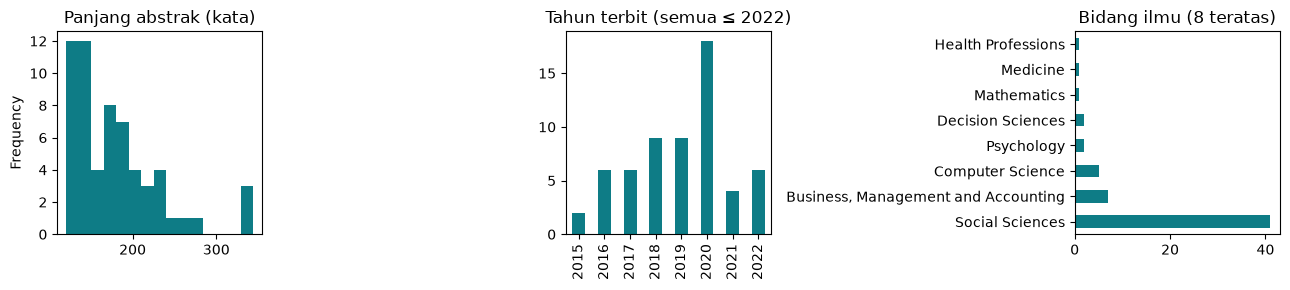

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
human_df["word_count"].plot.hist(bins=15, ax=axes[0], color="#0E7C86")
axes[0].set(title="Panjang abstrak (kata)", xlabel="")
human_df["year"].value_counts().sort_index().plot.bar(ax=axes[1], color="#0E7C86")
axes[1].set(title="Tahun terbit (semua ≤ 2022)", xlabel="")
human_df["field"].value_counts().head(8).plot.barh(ax=axes[2], color="#0E7C86")
axes[2].set(title="Bidang ilmu (8 teratas)", ylabel="")
plt.tight_layout()
plt.show()

## Tahap B. Sisi AI (Groq)

Butuh `GROQ_API_KEY` di `ai_experiment/.env`. Model hanya diberi **judul**, tidak pernah abstrak aslinya,
sehingga topik terkunci sama di kedua sisi dan hasilnya bukan parafrase. Empat gaya prompt:

In [6]:
for nama, templat in generate.PROMPT_VARIANTS.items():
    print(f"[{nama}] {templat}\n")

[formal] Tuliskan abstrak ilmiah berbahasa Indonesia untuk penelitian berjudul "{title}". Panjang sekitar {words} kata. Gunakan ragam akademik baku. Keluarkan hanya abstraknya, tanpa judul dan tanpa kata pengantar.

[structured] Buat abstrak penelitian berbahasa Indonesia untuk judul "{title}". Susun mengikuti alur latar belakang, metode, hasil, dan simpulan. Panjang sekitar {words} kata. Keluarkan hanya abstraknya.

[plain] Tulis ringkasan penelitian berbahasa Indonesia untuk judul "{title}" sepanjang kira kira {words} kata. Tulis mengalir dalam satu paragraf, hindari daftar berpoin. Keluarkan hanya ringkasannya.

[natural] Tulis abstrak berbahasa Indonesia untuk penelitian berjudul "{title}". Panjang sekitar {words} kata. Tulis seperti mahasiswa yang menyusun abstrak skripsinya sendiri, jangan terlalu kaku dan jangan memakai frasa transisi yang berlebihan. Keluarkan hanya abstraknya.



Keluaran model dibersihkan sebelum dipakai: blok `<think>`, label `Judul:`/`Abstrak:`, tanda markdown.
Pembersih label dulu pernah menghapus seluruh abstrak ketika model membalas satu baris berawalan
`Abstrak: `, dan kegagalan itu **sistematis** (satu kombinasi model × prompt hilang seluruhnya, sekitar 8%
sampel). Berikut tiga kasus yang kini dikunci tes:

In [7]:
kasus = {
    "satu baris berlabel": "Abstrak: Penelitian ini membahas pengaruh pupuk terhadap hasil panen padi di lahan basah.",
    "judul lalu abstrak": "Judul: Pupuk dan Hasil Panen\nAbstrak: Penelitian ini membahas pengaruh pupuk terhadap hasil panen.",
    "blok berpikir": "<think>saya harus menulis abstrak</think>Penelitian ini membahas pengaruh pupuk terhadap hasil panen.",
}
pd.DataFrame({"mentah": kasus, "bersih": {k: generate.clean_generated(v) for k, v in kasus.items()}})

,mentah,bersih
satu baris berlabel,Abstrak: Penelitian ini membahas pengaruh pupuk terhadap hasil panen padi di lahan basah.,Penelitian ini membahas pengaruh pupuk terhadap hasil panen padi di lahan basah.
judul lalu abstrak,Judul: Pupuk dan Hasil Panen\nAbstrak: Penelitian ini membahas pengaruh pupuk terhadap...,Penelitian ini membahas pengaruh pupuk terhadap hasil panen.
blok berpikir,<think>saya harus menulis abstrak</think>Penelitian ini membahas pengaruh pupuk terhad...,Penelitian ini membahas pengaruh pupuk terhadap hasil panen.


In [8]:
GENERATE_AI = bool(config.GROQ_API_KEY)
if not GENERATE_AI:
    print("GROQ_API_KEY kosong: tahap B dilewati. Isi ai_experiment/.env lalu jalankan ulang sel ini.")
    ai_rows = bgs.load_jsonl(config.AI_CACHE)
else:
    models = bgs.validate_models(list(config.DEFAULT_MODELS))
    ai_rows = bgs.collect_ai(human, models, INCLUDE_MIXED, SEED, SLEEP) if models else bgs.load_jsonl(config.AI_CACHE)
print(f"{len(ai_rows)} teks AI di cache")

GROQ_API_KEY kosong: tahap B dilewati. Isi ai_experiment/.env lalu jalankan ulang sel ini.
0 teks AI di cache


## Tahap C. Gabungkan, pisahkan train/test, periksa mutu

Pemisahan berdasarkan `openalex_id` lewat hash, jadi deterministik dan pasangan manusia-AI dari judul yang
sama tidak pernah terbelah di sisi train dan test.

In [9]:
rows = list(human) + [r for r in ai_rows if r["openalex_id"] in {h["openalex_id"] for h in human}]
if not ai_rows:
    print("Belum ada sisi AI, jadi gold_set.csv belum ditulis (satu kelas tidak bisa dievaluasi).")
else:
    bgs.write_csv(rows, GOLD, SPLIT_BY)
    gold = pd.read_csv(GOLD)
    print(f"{GOLD.relative_to(ROOT)}: {len(gold)} baris")
    display(gold.groupby(["label", "split"]).size().unstack(fill_value=0))

Belum ada sisi AI, jadi gold_set.csv belum ditulis (satu kelas tidak bisa dievaluasi).


In [10]:
if GOLD.exists():
    gold = pd.read_csv(GOLD)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for label, warna in (("human", "#0E7C86"), ("ai", "#D9534F")):
        gold.loc[gold.label == label, "word_count"].plot.hist(bins=20, alpha=0.6, ax=axes[0], color=warna, label=label)
    axes[0].set(title="Panjang per kelas: harus berimpit", xlabel="kata")
    axes[0].legend()
    gold.loc[gold.label == "ai", "generator"].value_counts().plot.barh(ax=axes[1], color="#D9534F")
    axes[1].set(title="Sebaran generator: harus rata", ylabel="")
    plt.tight_layout()
    plt.show()
    gap = abs(gold[gold.label == "human"].word_count.mean() - gold[gold.label == "ai"].word_count.mean())
    print(f"Selisih panjang rata-rata manusia vs AI: {gap:.0f} kata", "(PERINGATAN: > 30)" if gap > 30 else "(aman)")

## Empat jebakan yang sudah ditangani

Semuanya membuat hasil evaluasi tampak lebih bagus daripada kenyataan.

| Jebakan | Kenapa berbahaya | Penanganan | Bukti di data |
|---|---|---|---|
| **Kebocoran zaman** | sisi manusia pra-2022, sisi AI dibuat sekarang: detektor bisa mempelajari zaman atau topik, bukan gaya | model hanya diberi judul dokumen pra-2022, topik terkunci sama | kolom `title` sama di kedua sisi |
| **Kebocoran panjang** | teks AI sistematis lebih panjang/pendek: panjang jadi petunjuk gratis | diminta panjang yang sama; selisih rata-rata dilaporkan, peringatan bila > 30 kata | grafik panjang di atas |
| **Kebocoran generator** | seluruh sisi AI dari satu model dan satu prompt: yang dipelajari adalah jejak prompt | 3 model × 4 gaya prompt, kolom `generator` dan `prompt_variant` disimpan | grafik sebaran generator |
| **Kebocoran pasangan** | abstrak manusia dan padanan AI-nya jatuh di sisi train/test berbeda | pemisahan per `openalex_id` lewat hash | tabel split di atas |

**Soal jeda `SLEEP`.** Bukan kesopanan. Batas laju Groq dihitung per menit dan **per model**, dan model
terbesar punya jatah paling sempit. Tanpa jeda, permintaan menumpuk sampai model besar menjawab 429
sementara dua model kecil tetap lolos, sehingga yang hilang selalu generator yang sama. Uji jalan penuh
yang pertama kehilangan 30 sampel dengan cara ini (seluruhnya `llama-3.3-70b-versatile`), dan sebarannya
menjadi 136 berbanding 167 dan 167. **Selalu baca sebaran generator**; kalau timpang, naikkan `SLEEP` dan
jalankan ulang (cache membuatnya murah).

**Catatan generator.** `qwen/qwen3.6-27b` tidak dipakai bawaan: ia menuliskan proses berpikir dalam bahasa
Inggris tanpa tag `<think>` dan keluarannya membengkak sampai lima kali panjang yang diminta.
`gemma2-9b-it` sudah dihentikan penyedia. Karena itu `validate_models` memeriksa katalog sebelum mulai.

## Kesimpulan dan langkah berikutnya

`gold_set.csv` siap dipakai tahap 02 bila sisi manusia dan sisi AI sama-sama ada. Batasan yang berlaku
sampai notebook berikutnya: ini **abstrak**, bukan esai mahasiswa.